# Project 11: Handwritten Digit Classification Using CNN

**Goal:** Build a simple Convolutional Neural Network (CNN) that recognizes handwritten digits (0-9) from the MNIST dataset.

**Steps:**
1. Load and preprocess the data
2. Build and train the CNN
3. Evaluate the model (accuracy, confusion matrix, classification report, sample predictions)

## Step 0: Import Libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.utils import to_categorical

from sklearn.metrics import confusion_matrix, classification_report

## Task 1: Load and Preprocess the MNIST Dataset

MNIST has 70,000 grayscale images of size 28x28 pixels:
- 60,000 for training
- 10,000 for testing

In [2]:
# Load the dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Training images shape:", x_train.shape)
print("Training labels shape:", y_train.shape)
print("Testing images shape :", x_test.shape)
print("Testing labels shape :", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images shape: (60000, 28, 28)
Training labels shape: (60000,)
Testing images shape : (10000, 28, 28)
Testing labels shape : (10000,)


### Look at some sample images

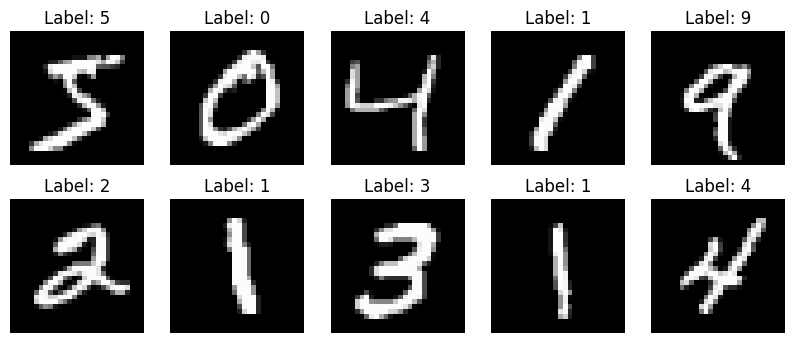

In [3]:
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title("Label: " + str(y_train[i]))
    plt.axis('off')
plt.show()

### Preprocessing

1. **Normalize** - pixel values go from 0-255 to 0-1 (helps the model learn faster).
2. **Reshape** - CNN needs images as (height, width, channels). MNIST is grayscale, so channels = 1.
3. **One-hot encode** the labels - e.g. digit 3 becomes `[0,0,0,1,0,0,0,0,0,0]`.

In [4]:
# 1. Normalize
x_train = x_train / 255.0
x_test = x_test / 255.0

# 2. Reshape to (28, 28, 1)
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

# 3. One-hot encode labels (we keep the original y_test for evaluation later)
y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

print("New training shape:", x_train.shape)
print("Example one-hot label:", y_train_cat[0])

New training shape: (60000, 28, 28, 1)
Example one-hot label: [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


## Task 2: Build and Train a Basic CNN

**Layers used:**
- `Conv2D` - finds patterns (edges, curves) in the image
- `MaxPooling2D` - shrinks the image while keeping important features
- `Flatten` - converts 2D features into a 1D list
- `Dense` - normal neural network layer for decision making
- `Dropout` - randomly turns off some neurons to avoid overfitting
- Last layer uses `softmax` to give a probability for each digit (0-9)

In [5]:
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(10, activation='softmax')
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

### Compile the model

In [6]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

### Train the model

In [7]:
history = model.fit(
    x_train, y_train_cat,
    epochs=5,
    batch_size=128,
    validation_split=0.1   # 10% of training data is used for validation
)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 14s 19ms/step - accuracy: 0.9236 - loss: 0.2541 - val_accuracy: 0.9822 - val_loss: 0.0613
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9763 - loss: 0.0773 - val_accuracy: 0.9883 - val_loss: 0.0460
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9842 - loss: 0.0542 - val_accuracy: 0.9908 - val_loss: 0.0344
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9869 - loss: 0.0415 - val_accuracy: 0.9897 - val_loss: 0.0405
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9895 - loss: 0.0348 - val_accuracy: 0.9902 - val_loss: 0.0310


### Training graphs (accuracy and loss)

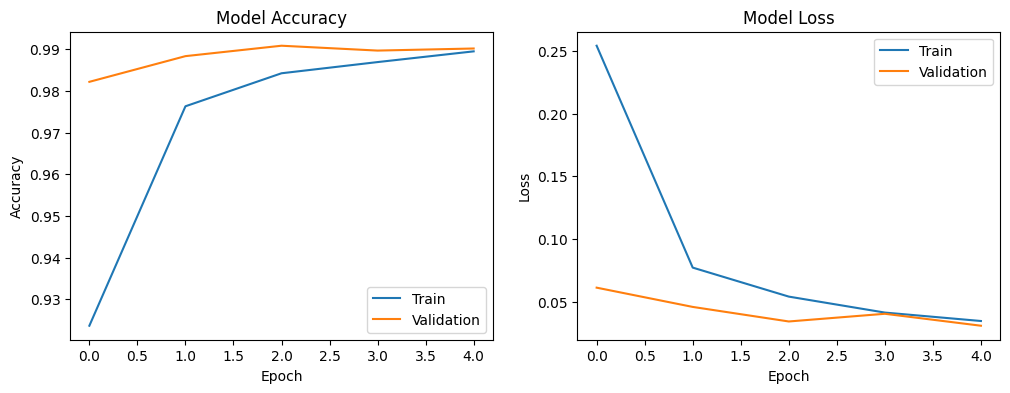

In [8]:
plt.figure(figsize=(12, 4))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

## Task 3: Evaluate the Model

### 3.1 Test Accuracy

In [9]:
test_loss, test_accuracy = model.evaluate(x_test, y_test_cat)
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9899 - loss: 0.0300
Test Accuracy: 98.99 %


### 3.2 Make predictions on the test set
The model gives 10 probabilities per image. `argmax` picks the digit with the highest probability.

In [10]:
y_pred_probs = model.predict(x_test)
y_pred = np.argmax(y_pred_probs, axis=1)

print("First 10 predictions :", y_pred[:10])
print("First 10 actual labels:", y_test[:10])

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
First 10 predictions : [7 2 1 0 4 1 4 9 5 9]
First 10 actual labels: [7 2 1 0 4 1 4 9 5 9]


### 3.3 Confusion Matrix
Each row is the **actual** digit and each column is the **predicted** digit.
Numbers outside the diagonal are mistakes.

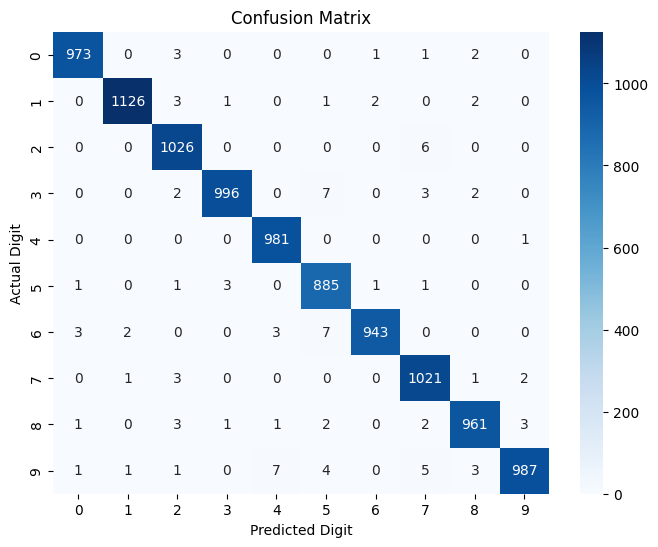

In [11]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted Digit')
plt.ylabel('Actual Digit')
plt.show()

### 3.4 Classification Report
Shows **precision**, **recall** and **F1-score** for every digit.

In [12]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       1.00      0.99      0.99      1135
           2       0.98      0.99      0.99      1032
           3       1.00      0.99      0.99      1010
           4       0.99      1.00      0.99       982
           5       0.98      0.99      0.98       892
           6       1.00      0.98      0.99       958
           7       0.98      0.99      0.99      1028
           8       0.99      0.99      0.99       974
           9       0.99      0.98      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



### 3.5 Which digits are misclassified most?

In [13]:
# Remove the correct predictions (diagonal) to see only the mistakes
mistakes = cm.copy()
np.fill_diagonal(mistakes, 0)

# Find the biggest mistake
actual, predicted = np.unravel_index(np.argmax(mistakes), mistakes.shape)
print("Most common mistake: digit", actual, "was predicted as", predicted,
      "->", mistakes[actual, predicted], "times")

# Total mistakes per actual digit
for digit in range(10):
    print("Digit", digit, "-> wrong predictions:", mistakes[digit].sum())

Most common mistake: digit 3 was predicted as 5 -> 7 times
Digit 0 -> wrong predictions: 7
Digit 1 -> wrong predictions: 9
Digit 2 -> wrong predictions: 6
Digit 3 -> wrong predictions: 14
Digit 4 -> wrong predictions: 1
Digit 5 -> wrong predictions: 7
Digit 6 -> wrong predictions: 15
Digit 7 -> wrong predictions: 7
Digit 8 -> wrong predictions: 13
Digit 9 -> wrong predictions: 22


### 3.6 Sample Predictions
Green title = correct prediction, red title = wrong prediction.

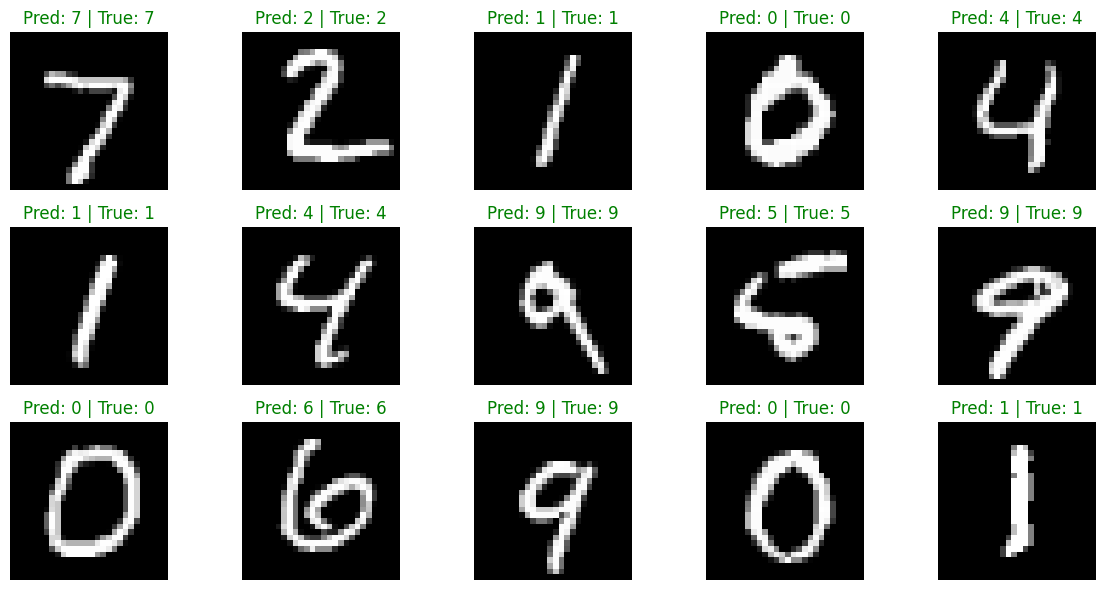

In [14]:
plt.figure(figsize=(12, 6))
for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')

    if y_pred[i] == y_test[i]:
        color = 'green'
    else:
        color = 'red'

    plt.title("Pred: " + str(y_pred[i]) + " | True: " + str(y_test[i]), color=color)
    plt.axis('off')

plt.tight_layout()
plt.show()

### 3.7 Look at some wrong predictions

Total wrong predictions: 101 out of 10000


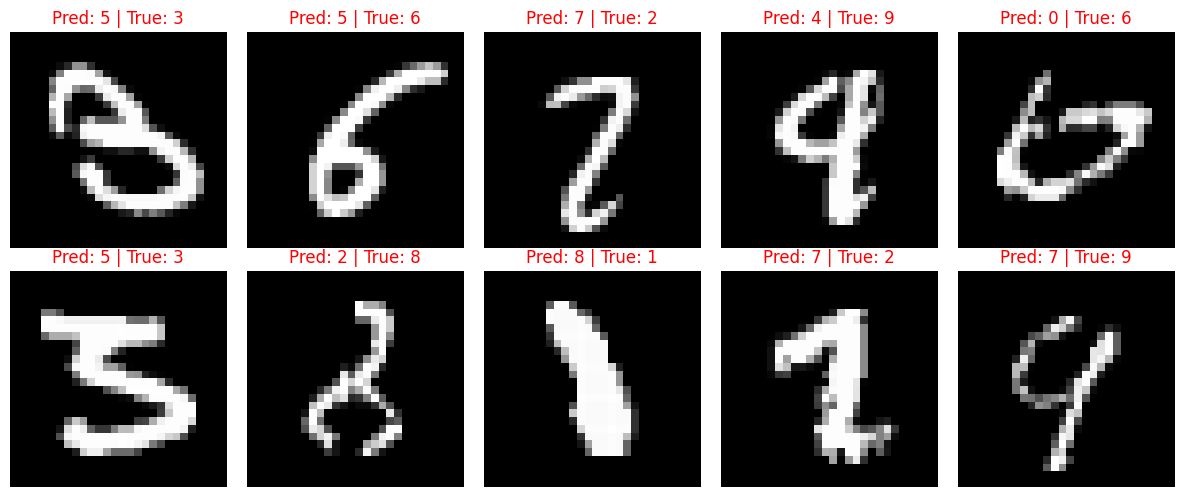

In [15]:
wrong_index = np.where(y_pred != y_test)[0]
print("Total wrong predictions:", len(wrong_index), "out of", len(y_test))

plt.figure(figsize=(12, 5))
for i in range(10):
    idx = wrong_index[i]
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[idx].reshape(28, 28), cmap='gray')
    plt.title("Pred: " + str(y_pred[idx]) + " | True: " + str(y_test[idx]), color='red')
    plt.axis('off')

plt.tight_layout()
plt.show()

## Save the Model (optional)

In [16]:
model.save('mnist_cnn_model.keras')
print("Model saved as mnist_cnn_model.keras")

Model saved as mnist_cnn_model.keras


## Conclusion

- We built a simple CNN with 2 convolution layers, 2 pooling layers and 2 dense layers.
- The model reached about **99% accuracy** on the MNIST test data.
- The **confusion matrix** showed which digits get mixed up (for example 4 and 9, or 3 and 5, because they look similar when handwritten).
- The **classification report** showed high precision, recall and F1-score for all 10 digits.